# A/B Testing

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

import warnings
warnings.simplefilter("ignore")

In [2]:
# polars
import polars as pl
from IPython.display import display
import numpy as np

def _append(base, extra):
    """Append a value or a Series onto a Series."""
    extra_s = extra if isinstance(extra, pl.Series) else pl.Series([extra])
    if base.len() == 0:
        return extra_s
    if base.dtype != extra_s.dtype:
        try:
            extra_s = extra_s.cast(base.dtype, strict=False)
        except Exception:
            base = base.cast(extra_s.dtype, strict=False)
    return pl.concat([base, extra_s])


## Comparing Two Samples

In [3]:
# datascience
births = Table.read_table('baby.csv')

In [4]:
# polars
births_pl = pl.read_csv('baby.csv', eol_char='\r')

In [5]:
# datascience
births

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True
108,282,23,67,125,True
136,286,25,62,93,False
138,244,33,62,178,False
132,245,23,65,140,False
120,289,25,62,125,False
143,299,30,66,136,True
140,351,27,68,120,False


In [6]:
# polars
births_pl

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
i64,i64,i64,i64,i64,bool
120,284,27,62,100,false
113,282,33,64,135,false
128,279,28,64,115,true
108,282,23,67,125,true
136,286,25,62,93,false
…,…,…,…,…,…
113,275,27,60,100,false
128,265,24,67,120,false
130,291,30,65,150,true


In [7]:
# datascience
smoking_and_birthweight = births.select('Maternal Smoker', 'Birth Weight')

In [8]:
# polars
smoking_and_birthweight_pl = births_pl.select('Maternal Smoker', 'Birth Weight')

In [9]:
# datascience
smoking_and_birthweight.group('Maternal Smoker')

Maternal Smoker,count
False,715
True,459


In [10]:
# polars
(lambda _df, _k='Maternal Smoker': _df.group_by(_k).len(name='count').sort(_k))(smoking_and_birthweight_pl)

Maternal Smoker,count
bool,u32
false,715
true,459


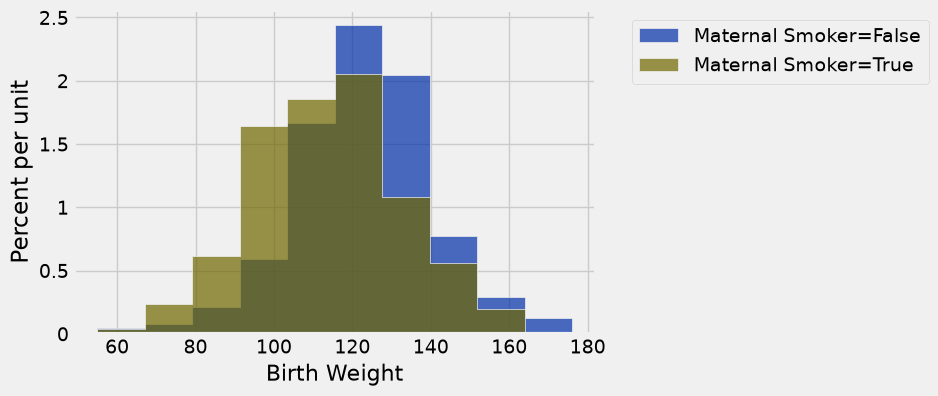

In [11]:
# datascience
smoking_and_birthweight.hist('Birth Weight', group='Maternal Smoker')

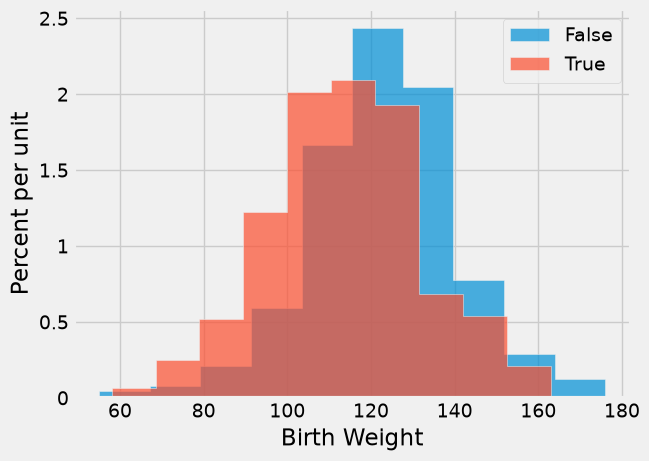

In [12]:
# polars
# matplotlib
_df = smoking_and_birthweight_pl
for _key, _part in _df.group_by('Maternal Smoker'):
    _label = _key[0] if isinstance(_key, tuple) else _key
    plots.hist(_part.get_column('Birth Weight').to_numpy(), density=True, histtype='stepfilled', alpha=0.7, label=str(_label))
plots.xlabel('Birth Weight')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))
plots.legend()

## Test Statistic

[Question] What values of our statistic are in favor of the alternative: positive or negative?

In [13]:
# datascience
means_table = smoking_and_birthweight.group('Maternal Smoker', np.average)
means_table

Maternal Smoker,Birth Weight average
False,123.085
True,113.819


In [14]:
# polars
means_table_pl = (lambda _df, _k='Maternal Smoker': _df.group_by(_k).agg([pl.col(c).mean().alias(f"{c} average") for c in _df.columns if c != _k and _df[c].dtype.is_numeric()]).sort(_k))(smoking_and_birthweight_pl)
means_table_pl

Maternal Smoker,Birth Weight average
bool,f64
false,123.085315
true,113.819172


In [15]:
# datascience
means = means_table.column(1)
observed_difference = means.item(1) - means.item(0)
observed_difference

-9.266142572024918

In [16]:
# polars
means_pl = means_table_pl.to_series(1)
observed_difference_pl = means_pl.item(1) - means_pl.item(0)
observed_difference_pl

-9.266142572024918

In [17]:
# datascience
def difference_of_means(table, numeric_label, category_label):
    """
    Takes: 
       - name of table
       - column label of numerical variable
       - column label of categorical variable
       
    Returns: Difference of means of the two groups
    """
    
    #table with the two relevant columns
    reduced = table.select(numeric_label, category_label)  
    
    # table containing group means
    means_table = reduced.group(category_label, np.average)
    
    # array of group means
    means = means_table.column(1)
    
    return means.item(1) - means.item(0)

In [18]:
# polars
def difference_of_means_pl(table, numeric_label, category_label):
    """
    Takes: 
       - name of table
       - column label of numerical variable
       - column label of categorical variable
       
    Returns: Difference of means of the two groups
    """
    
    #table with the two relevant columns
    reduced = table.select(numeric_label, category_label)  
    
    # table containing group means
    means_table_pl = (lambda _df, _k=category_label: _df.group_by(_k).agg([pl.col(c).mean().alias(f"{c} average") for c in _df.columns if c != _k and _df[c].dtype.is_numeric()]).sort(_k))(reduced)
    
    # array of group means
    means_pl = means_table_pl.to_series(1)
    
    return means_pl.item(1) - means_pl.item(0)

In [19]:
# datascience
difference_of_means(births, 'Birth Weight', 'Maternal Smoker')

-9.266142572024918

In [20]:
# polars
difference_of_means_pl(births_pl, 'Birth Weight', 'Maternal Smoker')

-9.266142572024918

## Random Permutation (Shuffling)

In [21]:
# datascience
staff = Table().with_columns(
    'Names', make_array('Jim', 'Pam', 'Dwight', 'Michael'),
    'Ages', make_array(29, 28, 34, 41)
)

In [22]:
# polars
staff_pl = pl.DataFrame({'Names': pl.Series("values", ['Jim', 'Pam', 'Dwight', 'Michael']), 'Ages': pl.Series("values", [29, 28, 34, 41])})

In [23]:
# datascience
staff.sample()

Names,Ages
Pam,28
Dwight,34
Pam,28
Pam,28


In [24]:
# polars
(lambda _df: _df.sample(n=_df.height, with_replacement=True, shuffle=True))(staff_pl)

Names,Ages
str,i64
"""Michael""",41
"""Jim""",29
"""Jim""",29
"""Pam""",28


In [25]:
# datascience
staff.sample(with_replacement = False)

Names,Ages
Dwight,34
Michael,41
Jim,29
Pam,28


In [26]:
# polars
(lambda _df: _df.sample(n=_df.height, with_replacement=False, shuffle=True))(staff_pl)

Names,Ages
str,i64
"""Dwight""",34
"""Pam""",28
"""Michael""",41
"""Jim""",29


In [27]:
# datascience
staff.with_column('Shuffled', staff.sample(with_replacement = False).column(0))

Names,Ages,Shuffled
Jim,29,Jim
Pam,28,Michael
Dwight,34,Pam
Michael,41,Dwight


In [28]:
# polars
staff_pl.with_columns(pl.Series('Shuffled', (lambda _df: _df.sample(n=_df.height, with_replacement=False, shuffle=True))(staff_pl).to_series(0)))

Names,Ages,Shuffled
str,i64,str
"""Jim""",29,"""Michael"""
"""Pam""",28,"""Jim"""
"""Dwight""",34,"""Pam"""
"""Michael""",41,"""Dwight"""


## Simulation Under Null Hypothesis

In [29]:
# datascience
smoking_and_birthweight

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136
False,138
False,132
False,120
True,143
False,140


In [30]:
# polars
smoking_and_birthweight_pl

Maternal Smoker,Birth Weight
bool,i64
false,120
false,113
true,128
true,108
false,136
…,…
false,113
false,128
true,130


In [31]:
# datascience
shuffled_labels = smoking_and_birthweight.sample(with_replacement=False).column('Maternal Smoker')

In [32]:
# polars
shuffled_labels_pl = (lambda _df: _df.sample(n=_df.height, with_replacement=False, shuffle=True))(smoking_and_birthweight_pl).get_column('Maternal Smoker')

In [33]:
# datascience
original_and_shuffled = smoking_and_birthweight.with_column(
    'Shuffled Label', shuffled_labels
)

In [34]:
# polars
original_and_shuffled_pl = smoking_and_birthweight_pl.with_columns(pl.Series('Shuffled Label', shuffled_labels_pl))

In [35]:
# datascience
original_and_shuffled

Maternal Smoker,Birth Weight,Shuffled Label
False,120,True
False,113,False
True,128,True
True,108,True
False,136,True
False,138,False
False,132,False
False,120,True
True,143,False
False,140,False


In [36]:
# polars
original_and_shuffled_pl

Maternal Smoker,Birth Weight,Shuffled Label
bool,i64,bool
false,120,true
false,113,false
true,128,false
true,108,true
false,136,false
…,…,…
false,113,false
false,128,false
true,130,true


In [37]:
# datascience
difference_of_means(original_and_shuffled, 'Birth Weight', 'Shuffled Label')

-0.16203970321616623

In [38]:
# polars
difference_of_means_pl(original_and_shuffled_pl, 'Birth Weight', 'Shuffled Label')

1.4012188247482413

In [39]:
# datascience
difference_of_means(original_and_shuffled, 'Birth Weight', 'Maternal Smoker')

-9.266142572024918

In [40]:
# polars
difference_of_means_pl(original_and_shuffled_pl, 'Birth Weight', 'Maternal Smoker')

-9.266142572024918

## Permutation Test

In [41]:
# datascience
def one_simulated_difference(table, numeric_label, category_label):
    """
    Takes: 
       - name of table
       - column label of numerical variable
       - column label of categorical variable
       
    Returns: Difference of means of the two groups
    """
    
    # array of shuffled labels
    shuffled_labels = table.sample(with_replacement = False).column(category_label)
    
    # table of numerical variable and shuffled labels
    shuffled_table = table.select(numeric_label).with_column('Shuffled Label', shuffled_labels)
    
    return difference_of_means(shuffled_table, numeric_label, 'Shuffled Label')   

In [42]:
# polars
def one_simulated_difference_pl(table, numeric_label, category_label):
    """
    Takes: 
       - name of table
       - column label of numerical variable
       - column label of categorical variable
       
    Returns: Difference of means of the two groups
    """
    
    # array of shuffled labels
    shuffled_labels_pl = (lambda _df: _df.sample(n=_df.height, with_replacement=False, shuffle=True))(table).get_column(category_label)
    
    # table of numerical variable and shuffled labels
    shuffled_table = table.select(numeric_label).with_columns(pl.Series('Shuffled Label', shuffled_labels_pl))
    
    return difference_of_means_pl(shuffled_table, numeric_label, 'Shuffled Label')   

In [43]:
# datascience
one_simulated_difference(births, 'Birth Weight', 'Maternal Smoker')

1.0613800143211876

In [44]:
# polars
one_simulated_difference_pl(births_pl, 'Birth Weight', 'Maternal Smoker')

-2.515870621752981

In [45]:
# datascience
differences = make_array()

for i in np.arange(2000):
    new_difference = one_simulated_difference(births, 'Birth Weight', 'Maternal Smoker')
    differences = np.append(differences, new_difference)

In [46]:
# polars
differences_pl = []

for i in pl.int_range(2000, eager=True):
    new_difference = one_simulated_difference_pl(births_pl, 'Birth Weight', 'Maternal Smoker')
    differences_pl.append(new_difference)
differences_pl = pl.Series("values", differences_pl)

Observed Difference: -9.266142572024918


Text(0.5, 1.0, 'Prediction Under the Null Hypothesis')

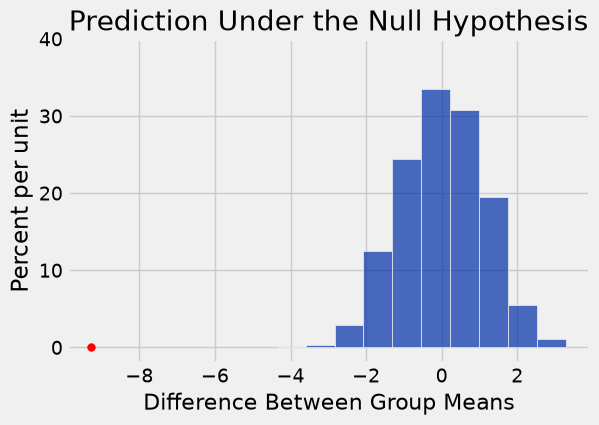

In [47]:
# datascience
Table().with_column('Difference Between Group Means', differences).hist()
plots.ylim(-.02, .4)
plots.scatter(observed_difference, 0, color='red', s=30);
print('Observed Difference:', observed_difference)
plots.title('Prediction Under the Null Hypothesis');

Observed Difference: -9.266142572024918


Text(0.5, 1.0, 'Prediction Under the Null Hypothesis')

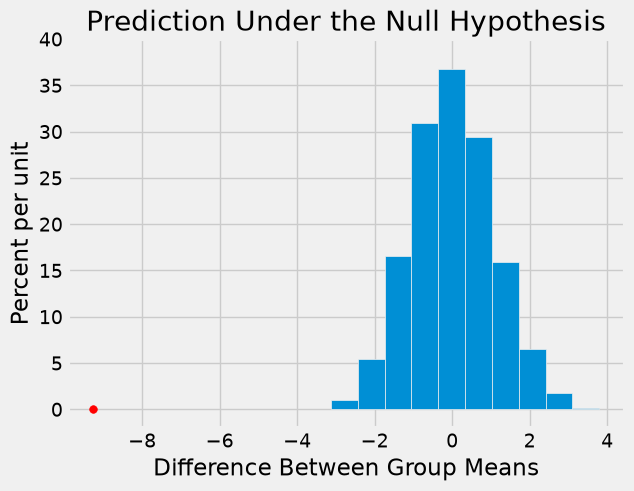

In [48]:
# polars
# matplotlib
_df = pl.DataFrame({'Difference Between Group Means': differences_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True)
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col)
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))
plots.ylim(-.02, .4)
plots.scatter(observed_difference_pl, 0, color='red', s=30);
print('Observed Difference:', observed_difference_pl)
plots.title('Prediction Under the Null Hypothesis');